In [3]:
from pathlib import Path
import tensorflow as tf
import numpy as np
import cv2

# Dataset location
DATASET_DIR = Path(r"C:\Users\adhil\OneDrive\Desktop\dfu\DFU_Classification_Project\data\dfu 4 class")

TRAIN_DIR = DATASET_DIR / "train"
VAL_DIR = DATASET_DIR / "valid"
TEST_DIR = DATASET_DIR / "test"

print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("OpenCV:", cv2.__version__)

print("\nDataset exists:", DATASET_DIR.exists())

for name, folder in [
    ("Train", TRAIN_DIR),
    ("Validation", VAL_DIR),
    ("Test", TEST_DIR)
]:
    print(f"\n{name} folder exists: {folder.exists()}")

    if folder.exists():
        for class_folder in sorted(folder.iterdir()):
            if class_folder.is_dir():
                count = sum(
                    1 for f in class_folder.rglob("*")
                    if f.suffix.lower() in {
                        ".jpg", ".jpeg", ".png", ".bmp", ".webp"
                    }
                )
                print(f"  {class_folder.name}: {count} images")

TensorFlow: 2.15.1
NumPy: 1.26.4
OpenCV: 4.10.0

Dataset exists: True

Train folder exists: True
  Grade 1: 2240 images
  Grade 2: 2345 images
  Grade 3: 2744 images
  Grade 4: 2310 images

Validation folder exists: True
  Grade 1: 86 images
  Grade 2: 78 images
  Grade 3: 40 images
  Grade 4: 78 images

Test folder exists: True
  Grade 1: 44 images
  Grade 2: 37 images
  Grade 3: 18 images
  Grade 4: 42 images


In [4]:

import tensorflow as tf
from tensorflow import keras
from pathlib import Path

IMG_SIZE = (300, 300)
BATCH_SIZE = 16
SEED = 42

CLASS_NAMES = ["Grade 1", "Grade 2", "Grade 3", "Grade 4"]

# Load the training dataset
train_ds = keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_names=CLASS_NAMES,
    label_mode="int",
    shuffle=True,
    seed=SEED
)

# Load the validation dataset
val_ds = keras.utils.image_dataset_from_directory(
    VAL_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_names=CLASS_NAMES,
    label_mode="int",
    shuffle=False
)

# Load the testing dataset
test_ds = keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_names=CLASS_NAMES,
    label_mode="int",
    shuffle=False
)

# Improve data-loading performance
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

print("\nAll datasets loaded successfully!")
print("Class names:", CLASS_NAMES)


Found 9639 files belonging to 4 classes.
Found 282 files belonging to 4 classes.
Found 141 files belonging to 4 classes.

All datasets loaded successfully!
Class names: ['Grade 1', 'Grade 2', 'Grade 3', 'Grade 4']


In [5]:

from tensorflow import keras
from tensorflow.keras import layers

# Load the pretrained EfficientNetB3 model
base_model = keras.applications.EfficientNetB3(
    include_top=False,
    weights="imagenet",
    input_shape=(300, 300, 3)
)

# Freeze pretrained layers during the first training stage
base_model.trainable = False

# Build the classification model
inputs = keras.Input(shape=(300, 300, 3), name="input_image")

# Data augmentation
x = layers.RandomFlip("horizontal")(inputs)
x = layers.RandomRotation(0.05)(x)

# Extract image features
x = base_model(x, training=False)

# Convert feature maps into a feature vector
x = layers.GlobalAveragePooling2D(
    name="global_average_pooling"
)(x)

# Reduce overfitting
x = layers.Dropout(0.35)(x)

# Predict one of four grades
outputs = layers.Dense(
    4,
    activation="softmax",
    name="grade_predictions"
)(x)

# Create the final model
model = keras.Model(
    inputs=inputs,
    outputs=outputs,
    name="DFU_EfficientNetB3"
)

# Configure training
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Display the architecture
model.summary()




Model: "DFU_EfficientNetB3"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_image (InputLayer)    [(None, 300, 300, 3)]     0         
                                                                 
 random_flip (RandomFlip)    (None, 300, 300, 3)       0         
                                                                 
 random_rotation (RandomRot  (None, 300, 300, 3)       0         
 ation)                                                          
                                                                 
 efficientnetb3 (Functional  (None, 10, 10, 1536)      10783535  
 )                                                               
                                                                 
 global_average_pooling (Gl  (None, 1536)              0         
 obalAveragePooling2D)                                           
                                              

In [6]:

from pathlib import Path
import json
import tensorflow as tf
from tensorflow import keras

# Create folders for saving the model
MODEL_DIR = Path("../models").resolve()
MODEL_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = MODEL_DIR / "dfu_grade_model.keras"
BEST_MODEL_PATH = MODEL_DIR / "dfu_grade_model_best.keras"
CLASS_NAMES_PATH = MODEL_DIR / "class_names.json"

# Save the class order used by the model
with open(CLASS_NAMES_PATH, "w", encoding="utf-8") as file:
    json.dump(CLASS_NAMES, file, indent=4)

# Save the best model according to validation loss
checkpoint = keras.callbacks.ModelCheckpoint(
    filepath=str(BEST_MODEL_PATH),
    monitor="val_loss",
    save_best_only=True,
    mode="min",
    verbose=1
)

# Stop when validation loss no longer improves
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True,
    mode="min",
    verbose=1
)

# Reduce learning rate if validation loss plateaus
reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=2,
    min_lr=1e-7,
    mode="min",
    verbose=1
)

callbacks = [
    checkpoint,
    early_stopping,
    reduce_lr
]

print("Training callbacks configured successfully.")
print("Best-model path:", BEST_MODEL_PATH)
print("Class names saved to:", CLASS_NAMES_PATH)


Training callbacks configured successfully.
Best-model path: C:\Users\adhil\OneDrive\Desktop\dfu\DFU_Classification_Project\models\dfu_grade_model_best.keras
Class names saved to: C:\Users\adhil\OneDrive\Desktop\dfu\DFU_Classification_Project\models\class_names.json


In [7]:

EPOCHS_HEAD = 8

history_head = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_HEAD,
    callbacks=callbacks,
    verbose=1
)

print("\nInitial training completed!")


Epoch 1/8


603/603 [==============================] - ETA: 0s - loss: 1.0903 - accuracy: 0.5320
Epoch 1: val_loss improved from inf to 0.94501, saving model to C:\Users\adhil\OneDrive\Desktop\dfu\DFU_Classification_Project\models\dfu_grade_model_best.keras
603/603 [==============================] - 413s 674ms/step - loss: 1.0903 - accuracy: 0.5320 - val_loss: 0.9450 - val_accuracy: 0.6383 - lr: 0.0010
Epoch 2/8
603/603 [==============================] - ETA: 0s - loss: 0.9284 - accuracy: 0.6215
Epoch 2: val_loss did not improve from 0.94501
603/603 [==============================] - 397s 658ms/step - loss: 0.9284 - accuracy: 0.6215 - val_loss: 0.9751 - val_accuracy: 0.6099 - lr: 0.0010
Epoch 3/8
603/603 [==============================] - ETA: 0s - loss: 0.8717 - accuracy: 0.6483
Epoch 3: val_loss did not improve from 0.94501

Epoch 3: ReduceLROnPlateau reducing learning rate to 0.00020000000949949026.
603/603 [==============================] - 405s 672ms/step - loss: 0.8717 - accuracy

In [8]:

# Step 1: Unfreeze the EfficientNetB3 base model
base_model.trainable = True

# Step 2: Keep most pretrained layers frozen
# Fine-tune only the last 30 layers
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Keep BatchNormalization layers frozen for stable fine-tuning
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

# Step 3: Recompile with a much smaller learning rate
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Fine-tuning configuration completed.")
print("Trainable parameters:", sum(
    tf.size(variable).numpy()
    for variable in model.trainable_variables
))


Fine-tuning configuration completed.
Trainable parameters: 3540926


In [9]:

EPOCHS_FINE_TUNE = 8

history_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_FINE_TUNE,
    callbacks=callbacks,
    verbose=1
)

print("\nFine-tuning completed!")


Epoch 1/8
603/603 [==============================] - ETA: 0s - loss: 0.8970 - accuracy: 0.6426
Epoch 1: val_loss improved from 0.94501 to 0.93364, saving model to C:\Users\adhil\OneDrive\Desktop\dfu\DFU_Classification_Project\models\dfu_grade_model_best.keras
603/603 [==============================] - 512s 836ms/step - loss: 0.8970 - accuracy: 0.6426 - val_loss: 0.9336 - val_accuracy: 0.6418 - lr: 1.0000e-05
Epoch 2/8
603/603 [==============================] - ETA: 0s - loss: 0.8109 - accuracy: 0.6742
Epoch 2: val_loss improved from 0.93364 to 0.93243, saving model to C:\Users\adhil\OneDrive\Desktop\dfu\DFU_Classification_Project\models\dfu_grade_model_best.keras
603/603 [==============================] - 510s 845ms/step - loss: 0.8109 - accuracy: 0.6742 - val_loss: 0.9324 - val_accuracy: 0.6489 - lr: 1.0000e-05
Epoch 3/8
603/603 [==============================] - ETA: 0s - loss: 0.7196 - accuracy: 0.7130
Epoch 3: val_loss did not improve from 0.93243
603/603 [=========================

In [10]:
from pathlib import Path
import tensorflow as tf
from tensorflow import keras

MODEL_PATH = Path(
    r"C:\Users\adhil\OneDrive\Desktop\dfu\DFU_Classification_Project\models\dfu_grade_model_best.keras"
)

best_model = keras.models.load_model(MODEL_PATH)

test_loss, test_accuracy = best_model.evaluate(test_ds, verbose=1)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.2%}")

9/9 [==============================] - 10s 710ms/step - loss: 0.9647 - accuracy: 0.6596
Test Loss: 0.9647
Test Accuracy: 65.96%


In [13]:

import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

# Get actual labels from the test dataset
y_true = np.concatenate([
    labels.numpy() for _, labels in test_ds
])

# Predict the grades
y_prob = best_model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

# Grade names
class_names = ["Grade 1", "Grade 2", "Grade 3", "Grade 4"]

# Display performance for each grade
print("CLASSIFICATION REPORT")
print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1, 2, 3],
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

# Display confusion matrix
print("CONFUSION MATRIX")
print(confusion_matrix(y_true, y_pred, labels=[0, 1, 2, 3]))


9/9 [==============================] - 8s 664ms/step
CLASSIFICATION REPORT
              precision    recall  f1-score   support

     Grade 1     0.6977    0.6818    0.6897        44
     Grade 2     0.6176    0.5676    0.5915        37
     Grade 3     0.4783    0.6111    0.5366        18
     Grade 4     0.7561    0.7381    0.7470        42

    accuracy                         0.6596       141
   macro avg     0.6374    0.6496    0.6412       141
weighted avg     0.6661    0.6596    0.6614       141

CONFUSION MATRIX
[[30  7  4  3]
 [ 8 21  5  3]
 [ 1  2 11  4]
 [ 4  4  3 31]]


In [12]:
%pip install scikit-learn

  Using cached scikit_learn-1.7.2-cp310-cp310-win_amd64.whl (8.9 MB)
  Using cached threadpoolctl-3.7.0-py3-none-any.whl (26 kB)
  Using cached scipy-1.15.3-cp310-cp310-win_amd64.whl (41.3 MB)
  Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)
Note: you may need to restart the kernel to use updated packages.


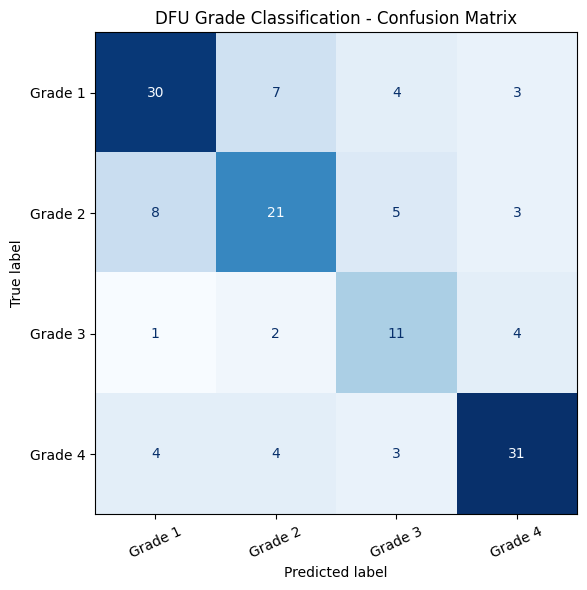

Confusion matrix saved to: C:\Users\adhil\OneDrive\Desktop\dfu\DFU_Classification_Project\outputs\evaluation\confusion_matrix.png


In [16]:

from pathlib import Path
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

# Output folder
OUTPUT_DIR = Path(
    r"C:\Users\adhil\OneDrive\Desktop\dfu\DFU_Classification_Project\outputs\evaluation"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

class_names = ["Grade 1", "Grade 2", "Grade 3", "Grade 4"]

cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2, 3])

fig, ax = plt.subplots(figsize=(8, 6))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

display.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

ax.set_title("DFU Grade Classification - Confusion Matrix")
plt.xticks(rotation=25)
plt.tight_layout()

save_path = OUTPUT_DIR / "confusion_matrix.png"
plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Confusion matrix saved to: {save_path}")


In [15]:
pip install matplotlib


  Using cached matplotlib-3.10.9-cp310-cp310-win_amd64.whl (8.2 MB)
  Using cached pillow-12.3.0-cp310-cp310-win_amd64.whl (7.2 MB)
  Using cached pyparsing-3.3.3-py3-none-any.whl (126 kB)
  Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
  Using cached kiwisolver-1.5.1-cp310-cp310-win_amd64.whl (70 kB)
  Using cached fonttools-4.65.0-cp310-cp310-win_amd64.whl (1.6 MB)
  Using cached contourpy-1.3.2-cp310-cp310-win_amd64.whl (221 kB)
